# Congestion pricing and New York taxi and ride-hail trips
Walk-through of the analysis behind the README. SQL runs live against the DuckDB warehouse built by `src/run_pipeline.py`; estimates are read from `reports/results.json`.

In [1]:
import os, sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config, data
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.width', 160)
results = json.loads(config.RESULTS_JSON.read_text())
T = lambda name: pd.read_csv(f'reports/tables/{name}.csv')

## 1. Data and cleaning
Rows read and kept per service and month (`sql/03_quality_checks.sql`).

In [2]:
q = T('quality_checks')
q.groupby('service')[['rows_read', 'rows_kept']].sum().assign(kept_share=lambda d: d.rows_kept / d.rows_read)

,rows_read,rows_kept,kept_share
service,,,
Uber/Lyft,241642415,231324393,0.9573
Yellow taxi,42139882,39556427,0.9387


In [3]:
data.row_counts()

{'zones': 265,
 'cbd_zones': 38,
 'trip_agg_rows': 5798838,
 'clean_trips': 270880820}

The 38 taxi zones in the Congestion Relief Zone, and how often each trip group carries the charge in Jan-Mar 2025.

In [4]:
display(data.query('SELECT zone_id, zone FROM zones WHERE in_cbd ORDER BY zone_id').head(10))
T('cbd_fee_share_after')

,zone_id,zone
0,4,Alphabet City
1,12,Battery Park
2,13,Battery Park City
3,45,Chinatown
4,48,Clinton East
5,50,Clinton West
6,68,East Chelsea
7,79,East Village
8,87,Financial District North
9,88,Financial District South


,service,trip_group,share_with_cbd_fee
0,Uber/Lyft,Elsewhere,0.0208
1,Uber/Lyft,Into zone,0.9841
2,Uber/Lyft,"Manhattan, outside zone",0.0605
3,Uber/Lyft,Out of zone,0.9891
4,Uber/Lyft,Within zone,0.9951
5,Yellow taxi,Elsewhere,0.0840
6,Yellow taxi,Into zone,0.9631
7,Yellow taxi,"Manhattan, outside zone",0.0971
8,Yellow taxi,Out of zone,0.9851
9,Yellow taxi,Within zone,0.9962


## 2. Trips this season and last

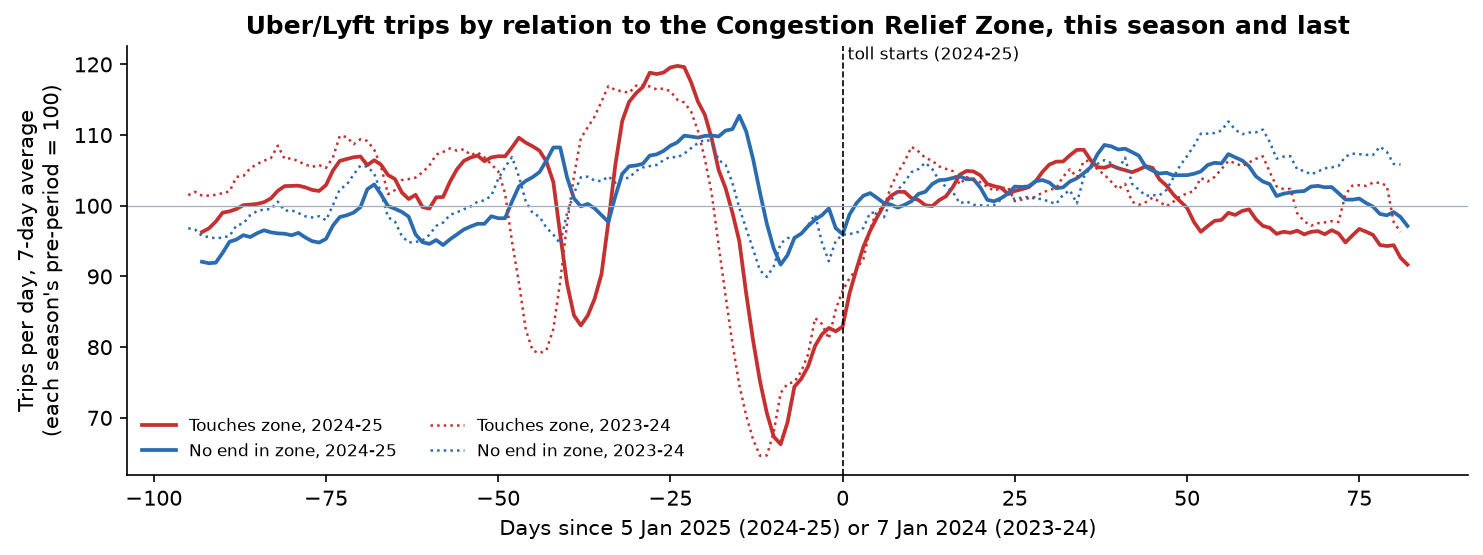

In [5]:
display(Image(filename='reports/figures/01_daily_trips_vs_last_year.png'))

In [6]:
cols = ['service', 'trip_group'] + [c for c in T('group_period_summary').columns if c.startswith('trips_')]
T('group_period_summary')[cols]

,service,trip_group,trips_per_day_2023-24_after,trips_per_day_2023-24_before,trips_per_day_2024-25_after,trips_per_day_2024-25_before,trips_change_2023-24,trips_change_2024-25,trips_change_net
0,Uber/Lyft,Elsewhere,"377,388.6235","362,517.1837","390,708.1628","380,418.3229",0.0410,0.0270,-0.0134
1,Uber/Lyft,Into zone,"54,887.9765","54,343.7143","52,748.0581","53,425.4792",0.0100,-0.0127,-0.0225
2,Uber/Lyft,"Manhattan, outside zone","38,528.7529","36,454.8673","37,916.2442","36,744.0729",0.0569,0.0319,-0.0236
3,Uber/Lyft,Out of zone,"64,396.5765","65,065.5102","62,565.6395","64,461.5625",-0.0103,-0.0294,-0.0193
4,Uber/Lyft,Within zone,"106,237.0941","102,189.2347","98,865.4767","97,294.9167",0.0396,0.0161,-0.0226
5,Yellow taxi,Elsewhere,"6,792.8706","7,124.1837","9,878.3953","8,495.2188",-0.0465,0.1628,0.2195
6,Yellow taxi,Into zone,"14,576.3529","15,413.6837","15,967.4535","16,911.6667",-0.0543,-0.0558,-0.0016
7,Yellow taxi,"Manhattan, outside zone","19,647.3294","20,096.0204","21,669.8605","22,025.5938",-0.0223,-0.0162,0.0063
8,Yellow taxi,Out of zone,"17,297.3765","18,419.8367","18,471.7558","19,043.1042",-0.0609,-0.0300,0.0329
9,Yellow taxi,Within zone,"42,591.3529","42,826.1939","49,233.2326","46,964.6875",-0.0055,0.0483,0.0541


## 3. Difference-in-differences on trips
Year-over-year change per flow, flow and week fixed effects, weights by pre-period volume, standard errors clustered by pickup zone.

In [7]:
rows = []
for s, e in results['estimates'].items():
    for label, r in [('main (no Thanksgiving weeks)', e['trips']['pooled']), ('all weeks', e['trips_all_weeks']),
                     ('unweighted', e['trips_unweighted']), ('placebo, fake start 1 Dec', e['placebo']),
                     ('single season (naive)', e['single_season']['estimate']),
                     ('single season placebo', e['single_season']['placebo'])]:
        rows.append({'service': s, 'estimate': label, 'effect_pct': r['effect_pct'], 'ci_low': r['effect_pct_low'],
                     'ci_high': r['effect_pct_high'], 'p_value': r['p_value']})
pd.DataFrame(rows)

,service,estimate,effect_pct,ci_low,ci_high,p_value
0,Uber/Lyft,main (no Thanksgiving weeks),-0.0065,-0.0146,0.0017,0.1180
1,Uber/Lyft,all weeks,-0.0104,-0.0183,-0.0025,0.0096
2,Uber/Lyft,unweighted,-0.0099,-0.0195,-0.0002,0.0445
3,Uber/Lyft,"placebo, fake start 1 Dec",0.0074,-0.0023,0.0172,0.1350
4,Uber/Lyft,single season (naive),-0.0185,-0.0289,-0.0079,0.0006
5,Uber/Lyft,single season placebo,-0.1345,-0.1475,-0.1213,0.0000
6,Yellow taxi,main (no Thanksgiving weeks),0.0198,0.0034,0.0365,0.0179
7,Yellow taxi,all weeks,0.0187,0.0043,0.0333,0.0105
8,Yellow taxi,unweighted,-0.1124,-0.1564,-0.0662,0.0000
9,Yellow taxi,"placebo, fake start 1 Dec",0.0206,-0.0060,0.0478,0.1302


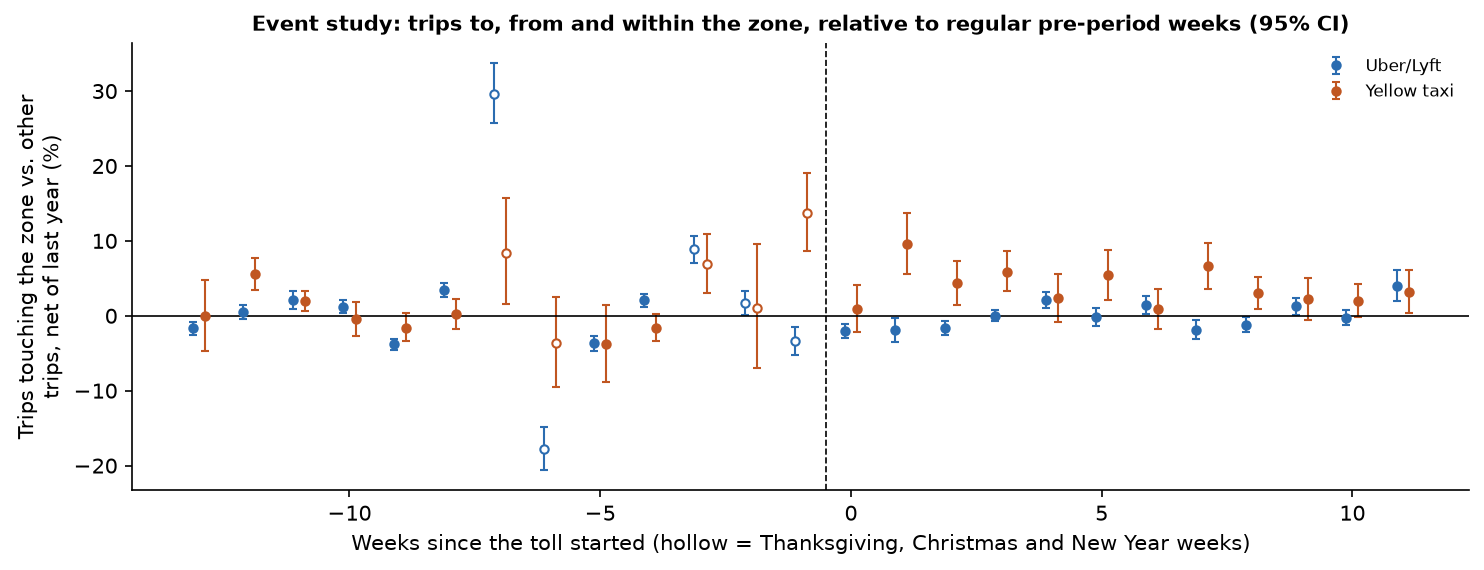

{'Uber/Lyft': {'wald_stat': 284.3857881213213,
  'df': 7,
  'p_value': 1.3022009445735818e-57,
  'regular_pre_weeks': [-13, -12, -11, -10, -9, -8, -5, -4],
  'max_abs_regular_pre_pct': 0.03794524675036259,
  'mean_post_pct': -0.00035809180109136474},
 'Yellow taxi': {'wald_stat': 74.68302725006717,
  'df': 7,
  'p_value': 1.6631902147411304e-13,
  'regular_pre_weeks': [-13, -12, -11, -10, -9, -8, -5, -4],
  'max_abs_regular_pre_pct': 0.05619171479738383,
  'mean_post_pct': 0.038427933153318605}}

In [8]:
display(Image(filename='reports/figures/02_event_study_trips.png'))
{s: e['pre_trend_test'] for s, e in results['estimates'].items()}

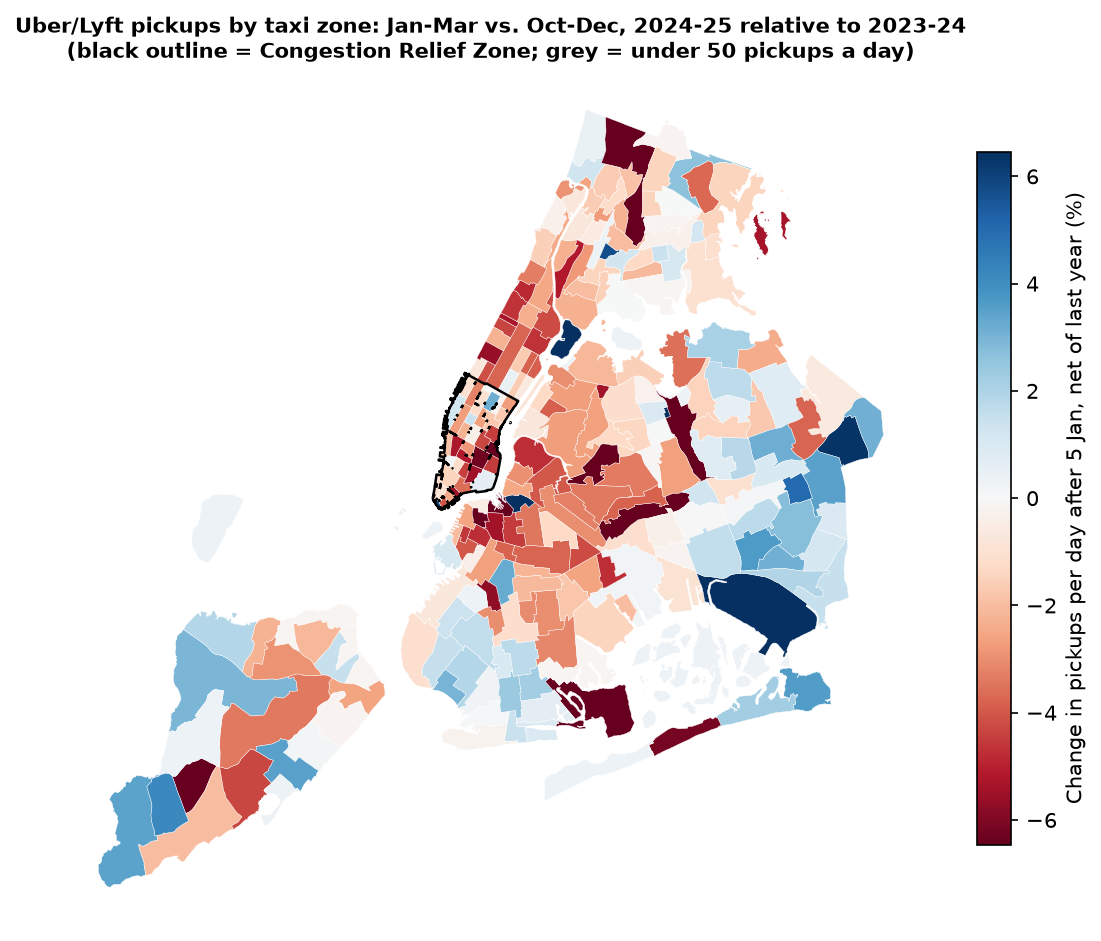

,zone,borough,in_cbd,trips_per_day_pre,change_net
135,LaGuardia Airport,Queens,False,"11,497.6458",-0.0155
129,JFK Airport,Queens,False,"9,039.6146",0.0944
60,Crown Heights North,Brooklyn,False,"8,398.3646",-0.0376
78,East Village,Manhattan,True,"8,210.7917",-0.0629
227,Times Sq/Theatre District,Manhattan,True,"7,166.3958",-0.0100
228,TriBeCa/Civic Center,Manhattan,True,"7,023.0417",-0.0141
158,Midtown Center,Manhattan,True,"7,021.7812",0.0316
36,Bushwick South,Brooklyn,False,"6,967.2396",-0.0298
75,East New York,Brooklyn,False,"6,946.2188",0.0024
67,East Chelsea,Manhattan,True,"6,787.5833",-0.0270


In [9]:
display(Image(filename='reports/figures/03_zone_map_change.png'))
T('zone_change').sort_values('trips_per_day_pre', ascending=False)[['zone', 'borough', 'in_cbd', 'trips_per_day_pre', 'change_net']].head(10)

## 4. Speeds

In [10]:
{s: {k: v for k, v in e['speed'].items() if k not in ('treated', 'control')} for s, e in results['estimates'].items()}

{'Uber/Lyft': {'coef': 0.040910179249893895,
  'std_error': 0.007955252752627593,
  'p_value': 2.7105346880225975e-07,
  'effect_pct': 0.041758529810444145,
  'effect_pct_low': 0.025641103456878866,
  'effect_pct_high': 0.058129233291249305,
  'single_season_effect_pct': 0.08804495237780752,
  'mph_treated_before': 8.149640418245218,
  'mph_treated_after': 9.02645722633512,
  'mph_control_before': 10.919372969049498,
  'mph_control_after': 11.122625966027575,
  'mph_treated_before_last_year': 8.2154214658544,
  'mph_treated_after_last_year': 8.745126388876466,
  'days': 181},
 'Yellow taxi': {'coef': 0.046991684237977734,
  'std_error': 0.011156566140597573,
  'p_value': 2.5309667423861374e-05,
  'effect_pct': 0.048113293182697525,
  'effect_pct_low': 0.025443102810401408,
  'effect_pct_high': 0.07128466936443312,
  'single_season_effect_pct': 0.09117290504104325,
  'mph_treated_before': 7.5426508095795795,
  'mph_treated_after': 8.715090592632185,
  'mph_control_before': 9.18188297976

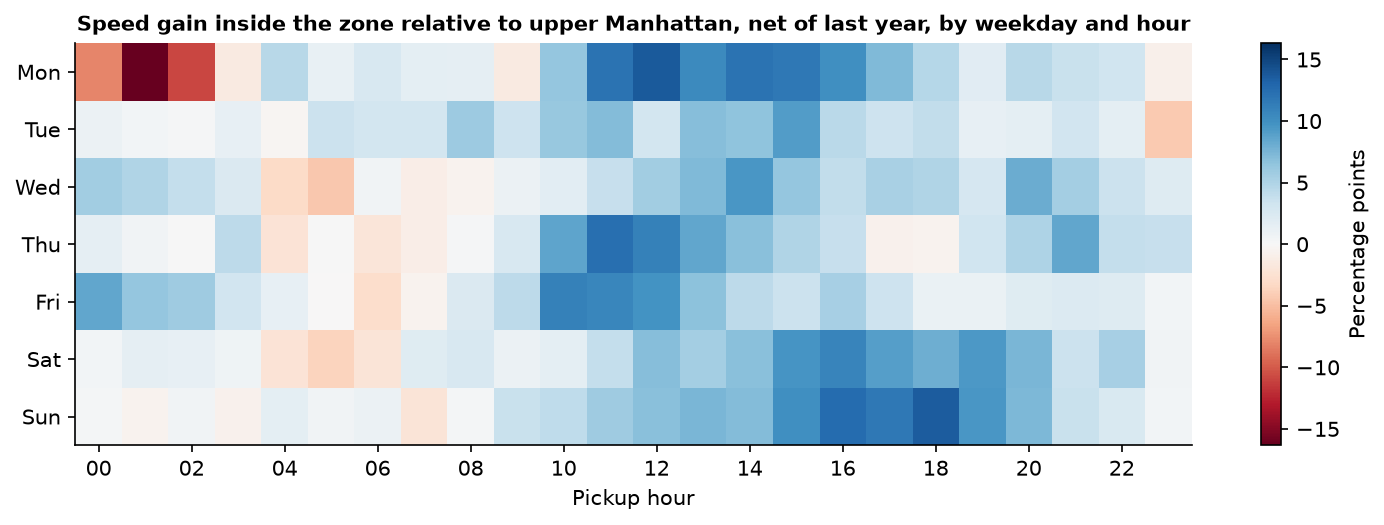

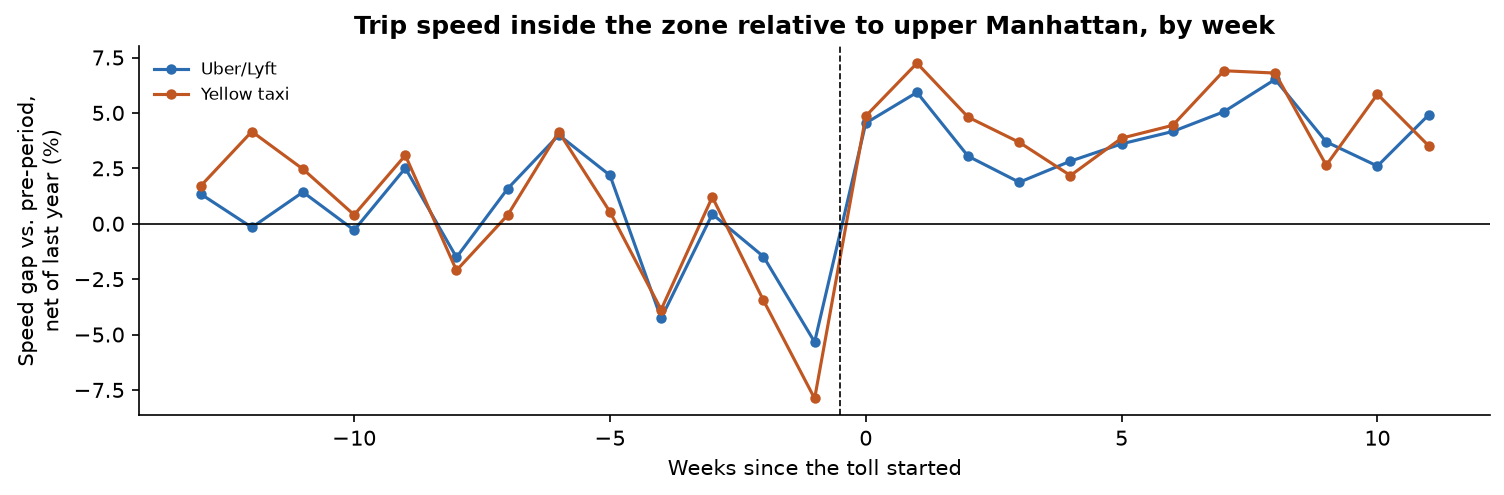

{'toll_peak_hours_pts': 0.05104655152994168,
 'overnight_hours_pts': 0.010856840747449338}

In [11]:
display(Image(filename='reports/figures/04_speed_change_heatmap.png'))
display(Image(filename='reports/figures/05_speed_gap_by_week.png'))
results['speed_by_toll_period']

## 5. Money per trip

In [12]:
pd.DataFrame(results['estimates']['Uber/Lyft']['money']).T

,coef,std_error,ci_low,ci_high,p_value,n_obs,treated_pre_mean_s1,effect_pct,effect_pct_low,effect_pct_high
passenger_cost_per_trip,0.6150,0.1970,0.2288,1.0011,0.0018,"11,983.0000",41.2068,NaN,NaN,NaN
base_fare_per_trip,-0.7213,0.1764,-1.0671,-0.3755,0.0000,"11,983.0000",33.1285,NaN,NaN,NaN
cbd_fee_per_trip,1.4482,0.0081,1.4323,1.4641,0.0000,"11,983.0000",0.0001,NaN,NaN,NaN
driver_pay_per_trip,-0.5542,0.0509,-0.6540,-0.4543,0.0000,"11,983.0000",24.0484,NaN,NaN,NaN
driver_pay_per_hour,0.9207,0.1006,0.7236,1.1179,0.0000,"11,983.0000",60.3024,NaN,NaN,NaN
mph,0.0494,0.0018,0.0458,0.0530,0.0000,"11,983.0000",NaN,0.0506,0.0468,0.0544


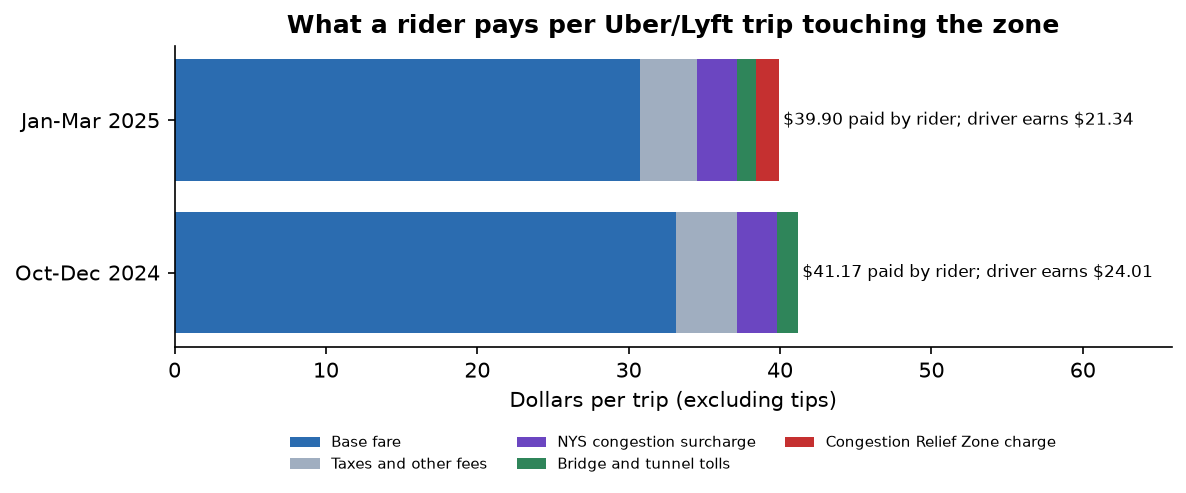

,season,service,touches_zone,period,trips,days,trips_per_day,base_fare,tolls,ny_surcharge,cbd_fee,other_fees,passenger_cost,tips,driver_pay,miles,minutes
0,2023-24,Uber/Lyft,False,Before,"39,099,261.0000",98,"398,972.0510",20.4480,0.4926,0.2545,0.0000,2.5925,23.7876,0.7677,16.5887,4.2882,17.4483
1,2023-24,Uber/Lyft,False,After,"35,352,977.0000",85,"415,917.3765",20.0385,0.4639,0.2519,0.0000,2.5328,23.2870,0.7087,16.1879,4.1706,16.8572
2,2023-24,Uber/Lyft,True,Before,"21,716,649.0000",98,"221,598.4592",30.1461,1.2642,2.6518,0.0000,3.7792,37.8413,1.7218,22.5702,5.0739,23.4783
3,2023-24,Uber/Lyft,True,After,"19,169,340.0000",85,"225,521.6471",28.4063,1.1866,2.6521,0.0000,3.5656,35.8106,1.5231,20.7473,4.9002,21.5533
4,2023-24,Yellow taxi,False,Before,"2,667,580.0000",98,"27,220.2041",19.8357,0.6661,1.8912,0.0000,2.9629,25.3559,3.4725,NaN,3.8587,15.2914
5,2023-24,Yellow taxi,False,After,"2,247,417.0000",85,"26,440.2000",19.0396,0.6249,1.8335,0.0000,2.9088,24.4068,3.2206,NaN,3.7420,14.5372
6,2023-24,Yellow taxi,True,Before,"7,512,652.0000",98,"76,659.7143",19.6837,0.5718,2.4099,0.0000,2.6048,25.2702,3.7039,NaN,3.2347,17.9103
7,2023-24,Yellow taxi,True,After,"6,329,532.0000",85,"74,465.0824",18.0979,0.4812,2.2984,0.0000,2.6554,23.5328,3.3604,NaN,3.0468,15.8418
8,2024-25,Uber/Lyft,False,Before,"40,047,590.0000",96,"417,162.3958",20.9734,0.5106,0.2440,0.0000,2.6217,24.3496,0.7479,17.1688,4.2734,17.5188
9,2024-25,Uber/Lyft,False,After,"36,861,699.0000",86,"428,624.4070",20.5688,0.4534,0.2408,0.0364,2.5270,23.8264,0.6656,16.3348,4.1205,16.6897


In [13]:
display(Image(filename='reports/figures/06_price_breakdown.png'))
T('unit_economics')

## 6. Memo

In [14]:
display(Markdown(open('reports/memo.md').read()))

# Memo: what congestion pricing did to ride-hail trips in Manhattan

**To:** Head of Pricing and Driver Operations · **Data:** 271 million TLC trips, Oct-Mar 2023-24 and 2024-25

**What we found**

- **Ride-hail demand for zone trips barely moved.** Uber/Lyft trips to, from and within the zone changed by -0.7% relative to trips with no end in the zone, net of last year's seasonal change (95% CI -1.5% to +0.2%). The interval includes zero. For scale, the MTA reports 11% fewer vehicles entering the zone in the toll's first year: ride-hail trips pay a $1.50 charge, not the $9 car toll, so their volume fell far less.
- **Trips inside the zone got faster.** Uber/Lyft trips with both ends in the zone sped up 4.2% relative to trips inside Manhattan north of 60th Street, net of last year (95% CI +2.6% to +5.8%); average speed went from 8.1 to 9.0 mph. Yellow taxis show the same gain (4.8%). The gain is 5.1 points in tolled peak hours against 1.1 overnight.
- **Riders paid $0.61 more per zone trip, not $1.50.** The zone charge added $1.45 per trip, but base fares fell $0.72 relative to other trips (net of last year), because faster trips take less time and both Uber/Lyft fares and TLC driver-pay rules include a per-minute component.
- **Drivers earned less per trip but more per hour.** Driver pay per zone trip fell $0.55 (-$0.65 to -$0.45), while pay per hour on trip rose $0.92 (+$0.72 to +$1.12) from a base of $60 per hour.
- **Yellow taxis: no clear change in zone trips.** The estimate is +2.0% (95% CI +0.3% to +3.6%), but a placebo start date in December gives +2.1%, so this is not evidence of riders switching to the cheaper $0.75 taxi charge.
- **A single-season before/after comparison would mislead.** Comparing Jan-Mar 2025 with Oct-Dec 2024 alone puts the speed gain at 8.8% (double the estimate net of last year) and fails a placebo test (-13.4% 'effect' at a fake start date), because Manhattan's holiday season moves zone trips differently. Using Oct-Mar 2023-24 as the seasonal baseline fixes this: the placebo gives +0.7% (p = 0.13).

**What to do**

1. Do not cut Uber/Lyft fares to offset the zone charge: zone trip volume held up, and riders' net price rose by less than half the charge because faster trips cost less.
2. Use the faster zone trips in driver supply messages: pay per hour on zone trips rose, so zone-specific driver bonuses are not needed to keep supply.
3. Review the time-based part of the fare and driver pay formulas: faster trips cut base fares by about $0.72 per zone trip.
4. Refresh the analysis as TLC publishes new months (about two months' delay) and watch the event study for a delayed demand response.

**Caveats:** observational design using last year as the baseline; trips through the zone without stopping are not identified; effects of a few percent are within weekly noise.
